# Clima no Brasil com os dados do INMET (2021 a 2024)

Projeto da disciplina Introdução a Big Data e Data Analytics, Parte 1: coleta, análise exploratória, limpeza e visualizações.


Fonte principal: INMET, dados históricos das estações automáticas

Página oficial: https://portal.inmet.gov.br/dadoshistoricos

Recorte: 2021 a 2024, todas as UFs, medições de hora em hora

Segunda fonte: IBGE (estados, municípios e malha das UFs) e NOAA (índice ONI do El Niño)

Volume: cerca de 20 milhões de linhas em 2.287 arquivos CSV


INMET (um zip por ano):

    data/bronze   zip original + Parquet bruto por ano e UF

    data/silver   dados limpos, padronizados e ligados ao IBGE e ao ONI

    data/gold     indicadores prontos para os gráficos

### Perguntas de pesquisa
1. A temperatura média subiu de 2021 para 2024? Em quais regiões subiu mais?
2. Como a chuva se distribui ao longo do ano em cada região e quais UFs ficaram mais secas ou mais chuvosas?
3. Quais UFs passaram mais tempo com calor extremo (% das horas acima de 35 °C) e isso mudou entre os anos?
4. Em quais meses e regiões a umidade do ar fica abaixo de 30%?
5. Os meses de El Niño foram diferentes dos meses de La Niña em temperatura e chuva?

In [1]:
# Bibliotecas do projeto
import sys, os, time, json, shutil, zipfile, unicodedata
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

# No Colab usa o Drive. Fora dele usa a pasta do projeto
try:
    from google.colab import drive
    drive.mount("/content/drive")
    # procura a pasta projeto_inmet na raiz do Drive ou dentro de uma pasta da raiz
    MEU_DRIVE = Path("/content/drive/MyDrive")
    candidatos = [MEU_DRIVE / "projeto_inmet"] + sorted(MEU_DRIVE.glob("*/projeto_inmet"))
    BASE = next((p for p in candidatos if (p / "src" / "coleta.py").exists()), candidatos[0])
    TMP_LOCAL = Path("/content/_tmp_inmet")   # disco da máquina do Colab, mais rápido que o Drive
except ModuleNotFoundError:
    BASE = Path.cwd().parent                  # o notebook fica em projeto_inmet/notebooks
    TMP_LOCAL = BASE / "data" / "_tmp"

# sem o script de coleta não dá para seguir
if not (BASE / "src" / "coleta.py").exists():
    raise FileNotFoundError(f"Não achei o src/coleta.py em {BASE}. Copie a pasta projeto_inmet inteira "
                            "para o Google Drive (MyDrive/projeto_inmet) e rode esta célula de novo.")

BRONZE = BASE / "data" / "bronze"
SILVER = BASE / "data" / "silver"
GOLD = BASE / "data" / "gold"
REPORTS = BASE / "reports"
FIGURAS = REPORTS / "figuras"
PASTA_INMET = BRONZE / "inmet"
SILVER_INMET = SILVER / "inmet"

for p in [BRONZE, SILVER, GOLD, FIGURAS, TMP_LOCAL]:
    p.mkdir(parents=True, exist_ok=True)

# o script de coleta fica em src/coleta.py
sys.path.insert(0, str(BASE / "src"))
import coleta

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

def tamanho_mb(pasta):
    return sum(f.stat().st_size for f in Path(pasta).rglob("*") if f.is_file()) / 1e6

def status():
    print("=" * 52)
    for nome, pasta in [("bronze", BRONZE), ("silver", SILVER), ("gold", GOLD)]:
        arqs = [f for f in pasta.rglob("*") if f.is_file() and f.name != ".gitkeep"]
        print(f"  data/{nome:<8} {len(arqs):>6} arquivos {tamanho_mb(pasta):>10,.1f} MB")
    print("=" * 52)

print("Pasta do projeto:", BASE)
status()


Mounted at /content/drive
Pasta do projeto: /content/drive/MyDrive/Geral/projeto_inmet
  data/bronze      120 arquivos      674.8 MB
  data/silver      112 arquivos      347.9 MB
  data/gold          3 arquivos        0.1 MB


## 1. Coleta

Os dados vêm da página de dados históricos do INMET. Cada ano é um zip com um CSV por estação. Cada CSV começa com 8 linhas com os dados da estação e depois vêm as medições de hora em hora.

São dados públicos e a página não fala de licença, então uso só para fins acadêmicos e citando a fonte. Também não existe dicionário oficial, por isso montei o meu a partir do cabeçalho dos CSVs (está no fim desta seção).

A coleta toda é feita pelo `src/coleta.py`:

| O que o script faz | Como |
|---|---|
| Não baixa de novo | se o zip já existe, pula |
| Tenta de novo se der erro | até 3 vezes |
| Não deixa arquivo pela metade | baixa como `.parcial` e renomeia no fim |
| Confere o zip | `zipfile.testzip()` |
| Converte para Parquet | um arquivo por ano e UF (`ano=2024/uf=SP`) |


In [2]:
# Baixa o que falta, converte para Parquet e baixa as fontes extras (IBGE e NOAA)
t0 = time.time()
meta = coleta.coletar(BASE, tmp_local=TMP_LOCAL)
print(f"\nColeta terminou em {time.time() - t0:.0f}s")

⏭️  2021.zip já existe (80.6 MB), pulando
⏭️  2021 já está em Parquet, pulando a conversão
⏭️  2022.zip já existe (90.4 MB), pulando
⏭️  2022 já está em Parquet, pulando a conversão
⏭️  2023.zip já existe (107.1 MB), pulando
⏭️  2023 já está em Parquet, pulando a conversão
⏭️  2024.zip já existe (102.8 MB), pulando
⏭️  2024 já está em Parquet, pulando a conversão
⏭️  estados.json já existe (0.0 MB), pulando
⏭️  municipios.json já existe (2.5 MB), pulando
⏭️  malha_uf.json já existe (0.1 MB), pulando
⏭️  oni.txt já existe (0.0 MB), pulando

Coleta terminou em 17s


### 1.1 Metadados da coleta
Data do download, URL, número de arquivos, linhas e colunas por arquivo e tamanho total. As tabelas estão salvas em `reports/`.

In [3]:
# Resumo da coleta por ano
resumo_coleta = (meta.groupby("ano")
                 .agg(arquivos=("arquivo", "count"), linhas=("linhas", "sum"), mb_csv=("mb_csv", "sum"))
                 .reset_index())
resumo_coleta["mb_zip"] = [round((BRONZE / "zip" / f"{a}.zip").stat().st_size / 1e6, 1) for a in resumo_coleta["ano"]]
resumo_coleta["mb_csv"] = resumo_coleta["mb_csv"].round(1)
resumo_coleta["baixado_em"] = meta.groupby("ano")["baixado_em"].first().values
resumo_coleta["url"] = [coleta.URL_INMET.format(ano=a) for a in resumo_coleta["ano"]]
display(resumo_coleta)

print(f"Total: {resumo_coleta['arquivos'].sum():,} arquivos | {resumo_coleta['linhas'].sum():,} linhas | "
      f"{resumo_coleta['mb_csv'].sum():,.0f} MB em CSV | {resumo_coleta['mb_zip'].sum():,.0f} MB em zip")
print(f"Colunas por arquivo: {meta['colunas'].unique().tolist()}")
print(f"Arquivos com menos horas que um ano inteiro: {(meta['linhas'] < 8760).sum()}")

meta.to_csv(REPORTS / "metadados_coleta_arquivos.csv", index=False)
resumo_coleta.to_csv(REPORTS / "metadados_coleta_resumo.csv", index=False)

print("\nAlguns arquivos da tabela de metadados:")
display(meta.head())

,ano,arquivos,linhas,mb_csv,mb_zip,baixado_em,url
0,2021,588,5150880,353.9,80.6,2026-11-14T17:30:18,https://portal.inmet.gov.br/uploads/dadoshisto...
1,2022,567,4948920,371.9,90.4,2026-11-14T17:32:04,https://portal.inmet.gov.br/uploads/dadoshisto...
2,2023,567,4966920,415.6,107.1,2026-11-14T17:34:11,https://portal.inmet.gov.br/uploads/dadoshisto...
3,2024,565,4962960,405.5,102.8,2026-11-14T17:36:12,https://portal.inmet.gov.br/uploads/dadoshisto...


Total: 2,287 arquivos | 20,029,680 linhas | 1,547 MB em CSV | 381 MB em zip
Colunas por arquivo: [19]
Arquivos com menos horas que um ano inteiro: 3

Alguns arquivos da tabela de metadados:


,ano,arquivo,uf,estacao,codigo_wmo,linhas,colunas,mb_csv,url,baixado_em
0,2021,INMET_CO_DF_A001_BRASILIA_01-01-2021_A_31-12-2...,DF,BRASILIA,A001,8760,19,0.810,https://portal.inmet.gov.br/uploads/dadoshisto...,2026-11-14T17:30:18
1,2021,INMET_CO_DF_A042_BRAZLANDIA_01-01-2021_A_31-12...,DF,BRAZLANDIA,A042,8760,19,0.797,https://portal.inmet.gov.br/uploads/dadoshisto...,2026-11-14T17:30:18
2,2021,INMET_CO_DF_A045_AGUAS EMENDADAS_01-01-2021_A_...,DF,AGUAS EMENDADAS,A045,8760,19,0.796,https://portal.inmet.gov.br/uploads/dadoshisto...,2026-11-14T17:30:18
3,2021,INMET_CO_DF_A046_GAMA (PONTE ALTA)_01-01-2021_...,DF,GAMA (PONTE ALTA),A046,8760,19,0.809,https://portal.inmet.gov.br/uploads/dadoshisto...,2026-11-14T17:30:18
4,2021,INMET_CO_DF_A047_PARANOA (COOPA-DF)_01-01-2021...,DF,PARANOA (COOPA-DF),A047,8760,19,0.798,https://portal.inmet.gov.br/uploads/dadoshisto...,2026-11-14T17:30:18


### 1.2 CSV × Parquet
Mesmo conteúdo nos dois formatos. O tempo de leitura é de um ano inteiro (2024).

In [4]:
# Tamanho em disco
mb_csv = meta["mb_csv"].sum()
mb_parquet = tamanho_mb(PASTA_INMET)

# Tempo para ler todos os CSVs de 2024 (de dentro do zip)
t0 = time.time()
linhas_csv = 0
with zipfile.ZipFile(BRONZE / "zip" / "2024.zip") as z:
    for m in z.infolist():
        if m.filename.upper().endswith(".CSV"):
            linhas_csv += len(coleta.ler_estacao(z, m.filename)[0])
t_csv = time.time() - t0

# Tempo para ler 2024 em Parquet
t0 = time.time()
df_pq = pd.read_parquet(PASTA_INMET / "ano=2024")
t_pq = time.time() - t0

comparacao = pd.DataFrame({
    "formato": ["CSV", "Parquet"],
    "tamanho_mb": [round(mb_csv, 1), round(mb_parquet, 1)],
    "leitura_2024_s": [round(t_csv, 1), round(t_pq, 1)],
    "linhas_2024": [linhas_csv, len(df_pq)],
})
display(comparacao)
print(f"O Parquet ficou {100 - mb_parquet / mb_csv * 100:.0f}% menor que o CSV e leu 2024 {t_csv / t_pq:.0f} vezes mais rápido.")
del df_pq

,formato,tamanho_mb,leitura_2024_s,linhas_2024
0,CSV,1546.8,31.0,4962960
1,Parquet,291.1,9.0,4962960


O Parquet ficou 81% menor que o CSV e leu 2024 3 vezes mais rápido.


### 1.3 Dicionário de dados
Nome original no CSV, nome novo usado na Silver, tipo, unidade, descrição e domínio.


In [5]:
# Nome original -> nome novo (snake_case, sem acento)
NOMES = dict(zip(coleta.COLUNAS_ORIGINAIS, [
    "data", "hora_utc", "precipitacao_mm", "pressao_mb", "pressao_max_mb", "pressao_min_mb",
    "radiacao_kj_m2", "temperatura_c", "orvalho_c", "temperatura_max_c", "temperatura_min_c",
    "orvalho_max_c", "orvalho_min_c", "umidade_max_pct", "umidade_min_pct", "umidade_pct",
    "vento_direcao_graus", "vento_rajada_ms", "vento_velocidade_ms",
]))
MEDIDAS = [NOMES[c] for c in coleta.MEDIDAS]

# Faixa de valores aceita para cada medida (fora disso é erro do sensor)
DOMINIO = {
    "precipitacao_mm": (0, 150), "pressao_mb": (700, 1050), "pressao_max_mb": (700, 1050),
    "pressao_min_mb": (700, 1050), "radiacao_kj_m2": (0, 5000), "temperatura_c": (-10, 50),
    "orvalho_c": (-30, 40), "temperatura_max_c": (-10, 50), "temperatura_min_c": (-10, 50),
    "orvalho_max_c": (-30, 40), "orvalho_min_c": (-30, 40), "umidade_max_pct": (0, 100),
    "umidade_min_pct": (0, 100), "umidade_pct": (0, 100), "vento_direcao_graus": (0, 360),
    "vento_rajada_ms": (0, 60), "vento_velocidade_ms": (0, 50),
}

linhas = [
    ("Data", "data", "texto (category)", "AAAA/MM/DD", "Data da medição em UTC", "datas do ano do arquivo"),
    ("Hora UTC", "hora_utc", "texto (category)", "HHMM UTC", "Hora da medição em UTC", "0000 UTC a 2300 UTC"),
    ("PRECIPITAÇÃO TOTAL, HORÁRIO (mm)", "precipitacao_mm", "float32", "mm", "Chuva acumulada na hora", "0 a 150"),
    ("PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)", "pressao_mb", "float32", "mB (hPa)", "Pressão do ar na altura da estação", "700 a 1050"),
    ("PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB)", "pressao_max_mb", "float32", "mB (hPa)", "Maior pressão na hora anterior", "700 a 1050"),
    ("PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB)", "pressao_min_mb", "float32", "mB (hPa)", "Menor pressão na hora anterior", "700 a 1050"),
    ("RADIACAO GLOBAL (Kj/m²)", "radiacao_kj_m2", "float32", "kJ/m²", "Energia do sol acumulada na hora (fica vazia à noite)", "0 a 5000"),
    ("TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)", "temperatura_c", "float32", "°C", "Temperatura do ar", "-10 a 50"),
    ("TEMPERATURA DO PONTO DE ORVALHO (°C)", "orvalho_c", "float32", "°C", "Temperatura em que o ar fica saturado", "-30 a 40"),
    ("TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C)", "temperatura_max_c", "float32", "°C", "Maior temperatura na hora anterior", "-10 a 50"),
    ("TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C)", "temperatura_min_c", "float32", "°C", "Menor temperatura na hora anterior", "-10 a 50"),
    ("TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C)", "orvalho_max_c", "float32", "°C", "Maior ponto de orvalho na hora anterior", "-30 a 40"),
    ("TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT) (°C)", "orvalho_min_c", "float32", "°C", "Menor ponto de orvalho na hora anterior", "-30 a 40"),
    ("UMIDADE REL. MAX. NA HORA ANT. (AUT) (%)", "umidade_max_pct", "float32", "%", "Maior umidade relativa na hora anterior", "0 a 100"),
    ("UMIDADE REL. MIN. NA HORA ANT. (AUT) (%)", "umidade_min_pct", "float32", "%", "Menor umidade relativa na hora anterior", "0 a 100"),
    ("UMIDADE RELATIVA DO AR, HORARIA (%)", "umidade_pct", "float32", "%", "Umidade relativa do ar", "0 a 100"),
    ("VENTO, DIREÇÃO HORARIA (gr) (° (gr))", "vento_direcao_graus", "float32", "graus", "De onde vem o vento (0 é norte)", "0 a 360"),
    ("VENTO, RAJADA MAXIMA (m/s)", "vento_rajada_ms", "float32", "m/s", "Rajada mais forte na hora", "0 a 60"),
    ("VENTO, VELOCIDADE HORARIA (m/s)", "vento_velocidade_ms", "float32", "m/s", "Velocidade média do vento", "0 a 50"),
    ("REGIAO (cabeçalho)", "regiao", "category", "sigla", "Região da estação", "N, NE, CO, SE, S"),
    ("UF (cabeçalho)", "uf", "category", "sigla", "Estado da estação", "27 UFs"),
    ("ESTACAO (cabeçalho)", "estacao", "category", "texto", "Nome da estação", "texto"),
    ("CODIGO (WMO) (cabeçalho)", "codigo_wmo", "category", "texto", "Código da estação no INMET", "letra e 3 números (ex.: A001)"),
    ("LATITUDE (cabeçalho)", "latitude", "float64", "graus", "Latitude da estação", "-34 a 6"),
    ("LONGITUDE (cabeçalho)", "longitude", "float64", "graus", "Longitude da estação", "-74 a -28"),
    ("ALTITUDE (cabeçalho)", "altitude", "float64", "m", "Altitude da estação", "0 a 3000"),
    ("(nome da pasta)", "ano", "int", "ano", "Ano do arquivo", "2021 a 2024"),
]
dicionario = pd.DataFrame(linhas, columns=["coluna_original", "coluna_nova", "tipo", "unidade", "descricao", "dominio"])
dicionario.to_csv(REPORTS / "dicionario_de_dados.csv", index=False)
display(dicionario)

,coluna_original,coluna_nova,tipo,unidade,descricao,dominio
0,Data,data,texto (category),AAAA/MM/DD,Data da medição em UTC,datas do ano do arquivo
1,Hora UTC,hora_utc,texto (category),HHMM UTC,Hora da medição em UTC,0000 UTC a 2300 UTC
2,"PRECIPITAÇÃO TOTAL, HORÁRIO (mm)",precipitacao_mm,float32,mm,Chuva acumulada na hora,0 a 150
3,"PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORAR...",pressao_mb,float32,mB (hPa),Pressão do ar na altura da estação,700 a 1050
4,PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB),pressao_max_mb,float32,mB (hPa),Maior pressão na hora anterior,700 a 1050
5,PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB),pressao_min_mb,float32,mB (hPa),Menor pressão na hora anterior,700 a 1050
6,RADIACAO GLOBAL (Kj/m²),radiacao_kj_m2,float32,kJ/m²,Energia do sol acumulada na hora (fica vazia à...,0 a 5000
7,"TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)",temperatura_c,float32,°C,Temperatura do ar,-10 a 50
8,TEMPERATURA DO PONTO DE ORVALHO (°C),orvalho_c,float32,°C,Temperatura em que o ar fica saturado,-30 a 40
9,TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C),temperatura_max_c,float32,°C,Maior temperatura na hora anterior,-10 a 50


## 2. Análise exploratória

A EDA olha a base **bruta** (Bronze) antes de qualquer limpeza. Então a ideia é conhecer os nossos dados e achar os problemas que a etapa 3 vai resolver.
Como tem mais de 20 milhões de linhas, as contas vão ser feitas ano por ano ou coluna por coluna, para não estourar a memória.

### 2.1 Visão geral

In [6]:
# Linhas, estações e UFs de cada ano
geral = pd.read_parquet(PASTA_INMET, columns=["ano", "uf", "codigo_wmo"])
colunas_arquivo = pq.read_schema(next(PASTA_INMET.rglob("*.parquet"))).names
print(f"Linhas: {len(geral):,}")
print(f"Colunas: {len(colunas_arquivo) + 2} (contando ano e uf, que viraram pastas)")
print(f"Estações diferentes: {geral['codigo_wmo'].nunique()} | UFs: {geral['uf'].nunique()}")
display(geral.groupby("ano", observed=True).agg(linhas=("uf", "size"), estacoes=("codigo_wmo", "nunique")))
del geral

Linhas: 20,029,680
Colunas: 27 (contando ano e uf, que viraram pastas)
Estações diferentes: 592 | UFs: 27


,linhas,estacoes
ano,,
2021,5150880,588
2022,4948920,567
2023,4966920,567
2024,4962960,565


In [7]:
# Tipos inferidos x tipos esperados: como o pandas lê o CSV se não passar nenhuma opção
with zipfile.ZipFile(BRONZE / "zip" / "2024.zip") as z:
    primeiro = next(m.filename for m in z.infolist() if m.filename.upper().endswith(".CSV"))
    cru = pd.read_csv(z.open(primeiro), sep=";", skiprows=8, encoding="latin-1")

tipos = pd.DataFrame({"tipo_inferido": cru.dtypes.astype(str)})
tipos["tipo_esperado"] = ["texto (data)", "texto (hora)"] + ["número decimal"] * 17 + ["coluna vazia"]
display(tipos)
print("Sem decimal=',' os números com vírgula viram texto (object). Por isso a coleta lê com decimal=','.")

,tipo_inferido,tipo_esperado
Data,object,texto (data)
Hora UTC,object,texto (hora)
"PRECIPITAÇÃO TOTAL, HORÁRIO (mm)",object,número decimal
"PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)",object,número decimal
PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB),object,número decimal
PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB),object,número decimal
RADIACAO GLOBAL (Kj/m²),object,número decimal
"TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)",object,número decimal
TEMPERATURA DO PONTO DE ORVALHO (°C),object,número decimal
TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C),object,número decimal


Sem decimal=',' os números com vírgula viram texto (object). Por isso a coleta lê com decimal=','.


In [8]:
# Memória por coluna em um ano (2024)
df_2024 = pd.read_parquet(PASTA_INMET / "ano=2024")
mem = (df_2024.memory_usage(deep=True) / 1e6).round(1).sort_values(ascending=False)
display(mem.rename("MB").to_frame().head(10))
print(f"Total em memória de 2024: {mem.sum():,.0f} MB para {len(df_2024):,} linhas")
print(f"Coluna Data como category: {df_2024['Data'].memory_usage(deep=True) / 1e6:,.0f} MB | "
      f"como texto comum: {df_2024['Data'].astype(str).memory_usage(deep=True) / 1e6:,.0f} MB")
del df_2024

,MB
longitude,39.7
latitude,39.7
altitude,39.7
RADIACAO GLOBAL (Kj/m²),19.9
"TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)",19.9
TEMPERATURA DO PONTO DE ORVALHO (°C),19.9
PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB),19.9
TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C),19.9
PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB),19.9
"PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)",19.9


Total em memória de 2024: 502 MB para 4,962,960 linhas
Coluna Data como category: 10 MB | como texto comum: 293 MB


### 2.2 Qualidade
Percentual de ausentes por coluna e por ano, linhas sem nenhuma medição, estações sem nenhum dado no ano, duplicados (mesma estação, data e hora), datas inválidas e valores fora do domínio do dicionário.

In [9]:
# Uma passada por ano calculando todos os indicadores de qualidade
ausentes, qualidade, fora = {}, [], []
for ano in coleta.ANOS:
    d = pd.read_parquet(PASTA_INMET / f"ano={ano}").rename(columns=NOMES)

    ausentes[ano] = (d[MEDIDAS].isna().mean() * 100).round(1)

    vazia = d[MEDIDAS].isna().all(axis=1)
    vazia_por_estacao = vazia.groupby(d["codigo_wmo"], observed=True).mean()
    datas = pd.to_datetime(d["data"].astype(str), format="%Y/%m/%d", errors="coerce")

    qualidade.append({
        "ano": ano,
        "linhas": len(d),
        "sem_nenhuma_medicao": int(vazia.sum()),
        "pct_sem_medicao": round(vazia.mean() * 100, 1),
        "estacoes": d["codigo_wmo"].nunique(),
        "estacoes_sem_dado_no_ano": int((vazia_por_estacao == 1).sum()),
        "duplicados": int(d.duplicated(subset=["codigo_wmo", "data", "hora_utc"]).sum()),
        "datas_invalidas": int(datas.isna().sum()),
        "data_de_outro_ano": int((datas.dt.year != ano).sum()),
    })
    for c, (minimo, maximo) in DOMINIO.items():
        fora.append({"ano": ano, "variavel": c, "abaixo_do_minimo": int((d[c] < minimo).sum()),
                     "acima_do_maximo": int((d[c] > maximo).sum())})
    del d, datas

tab_ausentes = pd.DataFrame(ausentes)
tab_qualidade = pd.DataFrame(qualidade)
tab_fora = pd.DataFrame(fora).groupby("variavel")[["abaixo_do_minimo", "acima_do_maximo"]].sum()

print("Problemas por ano:")
display(tab_qualidade)
print("% de ausentes por coluna e por ano:")
display(tab_ausentes)
print("Valores fora do domínio (somando os 4 anos):")
display(tab_fora[tab_fora.sum(axis=1) > 0])

Problemas por ano:


,ano,linhas,sem_nenhuma_medicao,pct_sem_medicao,estacoes,estacoes_sem_dado_no_ano,duplicados,datas_invalidas,data_de_outro_ano
0,2021,5150880,2197395,42.7,588,96,0,0,0
1,2022,4948920,1508078,30.5,567,30,0,0,0
2,2023,4966920,742386,14.9,567,14,0,0,0
3,2024,4962960,884433,17.8,565,20,0,0,0


% de ausentes por coluna e por ano:


,2021,2022,2023,2024
precipitacao_mm,49.5,36.2,22.2,26.3
pressao_mb,42.9,30.9,15.3,18.3
pressao_max_mb,43.1,31.1,15.4,18.4
pressao_min_mb,43.1,31.1,15.4,18.4
radiacao_kj_m2,66.6,59.5,49.0,49.5
temperatura_c,42.8,31.3,15.7,18.8
orvalho_c,45.8,34.5,19.7,24.3
temperatura_max_c,43.1,31.5,15.7,18.9
temperatura_min_c,43.0,31.5,15.7,18.9
orvalho_max_c,46.1,34.7,19.8,24.5


Valores fora do domínio (somando os 4 anos):


,abaixo_do_minimo,acima_do_maximo
variavel,,
orvalho_c,188,106
orvalho_max_c,87,219
orvalho_min_c,131,19
radiacao_kj_m2,0,2510


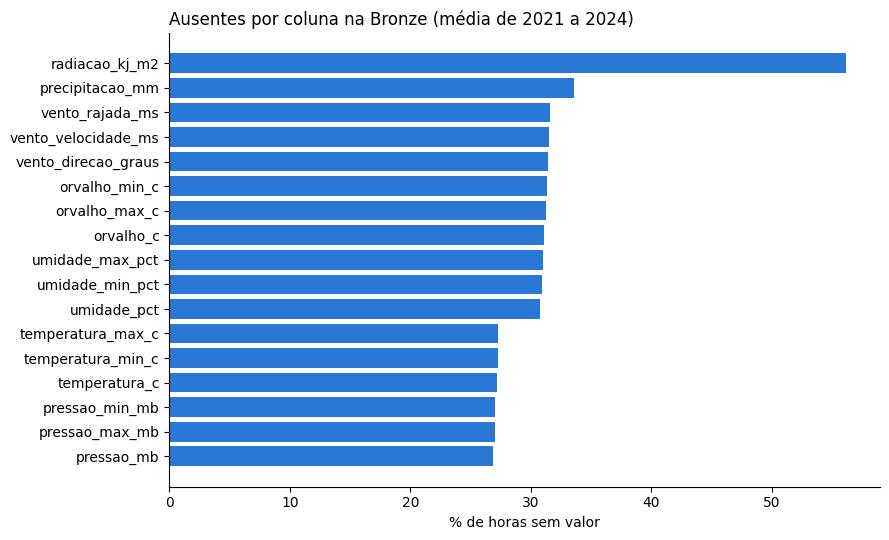

In [10]:
# Ausentes por coluna (média dos 4 anos)
aus = tab_ausentes.mean(axis=1).sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(aus.index, aus.values, color="#2a78d6")
ax.set_xlabel("% de horas sem valor")
ax.set_title("Ausentes por coluna na Bronze (média de 2021 a 2024)", loc="left")
plt.tight_layout(); plt.show()

### 2.3 Análise univariada
Medidas de posição e dispersão das principais variáveis, frequências das categóricas e outliers por IQR e por z-score.

In [11]:
# Estatísticas das principais medições (todos os anos, uma coluna por vez)
principais = ["temperatura_c", "umidade_pct", "precipitacao_mm", "pressao_mb",
              "radiacao_kj_m2", "vento_velocidade_ms", "vento_rajada_ms"]
ORIGINAL = {novo: orig for orig, novo in NOMES.items()}

estat = {}
for c in principais:
    s = pd.read_parquet(PASTA_INMET, columns=[ORIGINAL[c]])[ORIGINAL[c]]
    estat[c] = s.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99])
    estat[c]["assimetria"] = s.skew()
    del s
tab_estat = pd.DataFrame(estat).round(2)
display(tab_estat)

,temperatura_c,umidade_pct,precipitacao_mm,pressao_mb,radiacao_kj_m2,vento_velocidade_ms,vento_rajada_ms
count,14567651.00,13836776.00,13277671.00,14623263.00,8767726.00,13694163.00,13679947.00
mean,23.38,71.40,0.16,962.91,1261.64,1.84,4.69
std,5.81,20.60,1.33,62.69,1119.07,1.59,2.95
min,-9.20,4.00,0.00,720.40,0.00,0.00,0.00
1%,8.10,21.00,0.00,857.80,0.00,0.00,0.00
25%,19.90,57.00,0.00,935.00,152.90,0.60,2.40
50%,23.50,75.00,0.00,967.10,1032.50,1.50,4.40
75%,27.20,89.00,0.00,995.10,2193.60,2.70,6.60
99%,35.70,100.00,4.20,1020.00,3766.80,6.80,12.80
max,45.00,100.00,138.20,1049.30,44010.00,27.70,46.00


In [12]:
# Frequências e cardinalidade das categóricas
cat = pd.read_parquet(PASTA_INMET, columns=["ano", "regiao", "uf", "codigo_wmo", "estacao"])
estacoes = cat.drop_duplicates(["ano", "codigo_wmo"])
print("Estações por região em cada ano:")
display(pd.crosstab(estacoes["regiao"], estacoes["ano"]))
print("Cardinalidade (valores diferentes):")
display(pd.Series({c: cat[c].nunique() for c in ["regiao", "uf", "codigo_wmo", "estacao"]}, name="valores_diferentes").to_frame())
print("UFs com mais e menos estações em 2024:")
uf_2024 = estacoes[estacoes["ano"] == 2024]["uf"].value_counts()
print(uf_2024.head(5).to_string(), "\n...\n", uf_2024.tail(5).to_string())
del cat

Estações por região em cada ano:


ano,2021,2022,2023,2024
regiao,,,,
CO,113,97,96,96
N,87,88,88,88
NE,145,144,142,141
S,94,93,95,94
SE,149,145,146,146


Cardinalidade (valores diferentes):


,valores_diferentes
regiao,5
uf,27
codigo_wmo,592
estacao,596


UFs com mais e menos estações em 2024:
uf
MG    68
BA    45
RS    44
SP    40
MT    38 
...
 uf
SE    6
DF    5
AP    4
RO    4
RR    1


In [13]:
# Outliers por IQR (1,5 x IQR) e por z-score (|z| > 3)
def outliers(c):
    s = pd.read_parquet(PASTA_INMET, columns=[ORIGINAL[c]])[ORIGINAL[c]].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    z = (s - s.mean()) / s.std()
    return {"variavel": c, "q1": q1, "q3": q3, "limite_inferior": q1 - 1.5 * iqr, "limite_superior": q3 + 1.5 * iqr,
            "pct_fora_iqr": ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100,
            "pct_z_maior_3": (z.abs() > 3).mean() * 100, "minimo": s.min(), "maximo": s.max()}

tab_outliers = pd.DataFrame([outliers(c) for c in ["temperatura_c", "umidade_pct", "precipitacao_mm", "vento_rajada_ms"]]).round(2)
display(tab_outliers)

,variavel,q1,q3,limite_inferior,limite_superior,pct_fora_iqr,pct_z_maior_3,minimo,maximo
0,temperatura_c,19.9,27.2,8.95,38.15,1.45,0.45,-9.2,45.0
1,umidade_pct,57.0,89.0,9.00,137.00,0.01,0.02,4.0,100.0
2,precipitacao_mm,0.0,0.0,0.00,0.00,7.28,1.04,0.0,138.2
3,vento_rajada_ms,2.4,6.6,-3.90,12.90,0.94,0.70,0.0,46.0


**O que os outliers mostram**

Usei IQR e z-score. O que achei:

* **Temperatura:** de -9,2 °C a 45 °C. É geada no Sul e onda de calor em 2023, então é real e fica.
* **Umidade:** quase nada fora do normal.
* **Chuva:** o IQR não funciona porque quase toda hora a chuva é zero. O máximo foi 138 mm numa hora, o que acontece em temporal, então fica.
* **Vento:** rajada de até 46 m/s. Acontece em ciclone, então fica.
* **Radiação:** o sol não passa de uns 4.900 kJ/m² numa hora e tem valor de até 44.010. Esses 2.510 valores viram nulo na limpeza.


### 2.4 Análise bivariada e temporal
Evolução mensal por região, correlação entre as variáveis numéricas e tabela cruzada de região com faixa de temperatura.

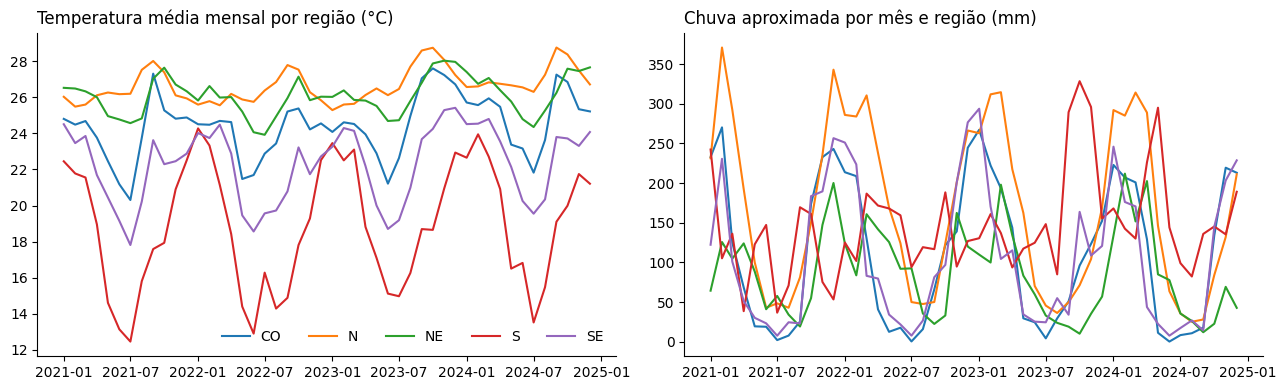

In [14]:
# Médias mensais por região, ano por ano (na Bronze a data ainda está em UTC)
partes = []
for ano in coleta.ANOS:
    d = pd.read_parquet(PASTA_INMET / f"ano={ano}", columns=["Data", "regiao", ORIGINAL["temperatura_c"],
                                                             ORIGINAL["precipitacao_mm"], ORIGINAL["umidade_pct"]]).rename(columns=NOMES)
    d["mes"] = d["data"].astype(str).str[5:7].astype(int)
    g = (d.groupby(["regiao", "mes"], observed=True)
          .agg(temperatura=("temperatura_c", "mean"), chuva_por_hora=("precipitacao_mm", "mean"), umidade=("umidade_pct", "mean"))
          .reset_index())
    g["ano"] = ano
    partes.append(g)
    del d
mensal_eda = pd.concat(partes, ignore_index=True)
mensal_eda["periodo"] = pd.to_datetime(dict(year=mensal_eda["ano"], month=mensal_eda["mes"], day=1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for reg, g in mensal_eda.groupby("regiao", observed=True):
    axes[0].plot(g["periodo"], g["temperatura"], label=reg)
    axes[1].plot(g["periodo"], g["chuva_por_hora"] * 24 * 30, label=reg)
axes[0].set_title("Temperatura média mensal por região (°C)", loc="left")
axes[1].set_title("Chuva aproximada por mês e região (mm)", loc="left")
axes[0].legend(ncol=5, frameon=False)
plt.tight_layout(); plt.show()

In [15]:
# Correlação entre as variáveis numéricas (amostra de 2024)
cols = ["temperatura_c", "orvalho_c", "umidade_pct", "pressao_mb", "radiacao_kj_m2", "vento_velocidade_ms", "precipitacao_mm"]
amostra = (pd.read_parquet(PASTA_INMET / "ano=2024", columns=[ORIGINAL[c] for c in cols])
             .rename(columns=NOMES).sample(frac=0.1, random_state=42))
corr = amostra.corr().round(2)
display(corr)

,temperatura_c,orvalho_c,umidade_pct,pressao_mb,radiacao_kj_m2,vento_velocidade_ms,precipitacao_mm
temperatura_c,1.00,0.39,-0.60,0.29,0.53,0.12,-0.05
orvalho_c,0.39,1.00,0.48,0.39,-0.07,-0.13,0.06
umidade_pct,-0.60,0.48,1.00,0.07,-0.55,-0.26,0.13
pressao_mb,0.29,0.39,0.07,1.00,-0.03,-0.06,-0.00
radiacao_kj_m2,0.53,-0.07,-0.55,-0.03,1.00,0.25,-0.11
vento_velocidade_ms,0.12,-0.13,-0.26,-0.06,0.25,1.00,0.02
precipitacao_mm,-0.05,0.06,0.13,-0.00,-0.11,0.02,1.00


In [16]:
# Tabela cruzada: em cada região, % das horas em cada faixa de temperatura (2024)
d = pd.read_parquet(PASTA_INMET / "ano=2024", columns=["regiao", ORIGINAL["temperatura_c"]]).rename(columns=NOMES).dropna()
d["faixa"] = pd.cut(d["temperatura_c"], bins=[-50, 10, 20, 25, 30, 35, 60],
                    labels=["até 10", "10 a 20", "20 a 25", "25 a 30", "30 a 35", "35 ou mais"])
cruzada = (pd.crosstab(d["regiao"], d["faixa"], normalize="index") * 100).round(1)
display(cruzada)
del d

faixa,até 10,10 a 20,20 a 25,25 a 30,30 a 35,35 ou mais
regiao,,,,,,
CO,0.5,15.0,38.9,27.6,15.1,2.8
N,0.0,2.7,32.6,40.8,21.3,2.7
NE,0.0,6.0,35.1,37.8,18.4,2.7
S,7.1,44.8,30.5,13.8,3.6,0.3
SE,0.9,26.9,39.5,23.6,8.3,0.7


### 2.5 Respostas preliminares

Ainda com a base bruta, antes da limpeza:

1. **Temperatura:** média de 23,4 °C. 2023 e 2024 parecem mais quentes que 2021 e 2022. Como as estações mudam de um ano para outro, a comparação certa vem depois, só com as estações dos 4 anos.
2. **Chuva:** o Norte chove mais. Centro-Oeste e Sudeste secam no meio do ano. O Sul chove o ano todo.
3. **Calor extremo:** em 2024, quase 3% das horas passaram de 35 °C no Centro-Oeste, no Norte e no Nordeste. No Sul foi 0,3%.
4. **Umidade:** chega a 4%. Cai quando esquenta (correlação de -0,60) e fica mais baixa de julho a setembro.
5. **El Niño:** 2021 e 2022 foram de La Niña e o El Niño começou no meio de 2023, justo quando vieram os meses mais quentes. A comparação vem depois da limpeza.


### 2.6 Lista de problemas (do mais grave para o mais leve)

| # | Problema | Quanto | O que fazer |
|---|---|---|---|
| 1 | Horas sem nenhuma medição (estação parada) | 5,3 milhões de linhas (26,6%). Em 2021, 96 estações ficaram o ano todo sem dado | Remover |
| 2 | Valores faltando | de 15% a 50% por coluna. A radiação passa de 49% porque fica vazia à noite | Deixar vazio e fazer as médias só com o que tem |
| 3 | Data e hora separadas e em UTC | todas as linhas | Juntar e passar para o horário de Brasília |
| 4 | Valores impossíveis | 2.510 de radiação (até 44.010) e 750 de orvalho | Trocar por nulo |
| 5 | Estações mudam de um ano para outro | 588 em 2021 e 565 em 2024 | Comparar só com as estações dos 4 anos |
| 6 | Colunas pesadas | a data ocupa 293 MB como texto e 10 MB como category | Usar float32 e category |
| 7 | Nomes de colunas longos e com acento | 19 colunas | Renomear em snake_case |
| 8 | Duplicados e datas erradas | nenhum | Deixar a regra mesmo assim |


## 3. Limpeza e tratamento

Cada problema da lista vira uma decisão, e eu conto quantas linhas cada uma afetou. A limpeza roda um ano por vez e salva a Silver em Parquet por ano e UF.

O que muda na Silver:
* nomes de colunas simples e tipos menores
* data e hora juntas, no horário de Brasília
* sem horas vazias e sem duplicados, e os valores impossíveis viram nulo
* colunas novas: mês, hora, estação do ano, faixa de temperatura, calor extremo (35 °C ou mais) e umidade baixa (abaixo de 30%)
* dados do IBGE (UF, região e município) e do ONI (El Niño ou La Niña no mês)


In [17]:
# Segunda fonte 1: estados do IBGE (sigla, nome, código e região)
estados_json = json.loads((BRONZE / "ibge" / "estados.json").read_text(encoding="utf-8"))
ESTADOS = pd.DataFrame([{"uf": e["sigla"], "nome_uf": e["nome"], "codigo_uf": e["id"],
                         "regiao_ibge": e["regiao"]["nome"], "sigla_regiao_ibge": e["regiao"]["sigla"]} for e in estados_json])

# Segunda fonte 2: municípios do IBGE para achar o município de cada estação
def normalizar(texto):
    # tira acento, deixa maiúsculo e sem espaços sobrando
    texto = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode()
    return " ".join(texto.upper().replace("'", " ").split())

mun_json = json.loads((BRONZE / "ibge" / "municipios.json").read_text(encoding="utf-8"))
MUNICIPIOS = pd.DataFrame([{"codigo_municipio": m["id"], "municipio": m["nome"],
                            "uf": m["microrregiao"]["mesorregiao"]["UF"]["sigla"] if m.get("microrregiao")
                                  else m["regiao-imediata"]["regiao-intermediaria"]["UF"]["sigla"]} for m in mun_json])
MUNICIPIOS["chave"] = MUNICIPIOS["municipio"].map(normalizar)

# Estações (todas que aparecem nos 4 anos). O nome da estação quase sempre é o nome do município.
ESTACOES = (pd.read_parquet(PASTA_INMET, columns=["codigo_wmo", "estacao", "uf"])
              .drop_duplicates("codigo_wmo").astype(str))
ESTACOES["chave"] = ESTACOES["estacao"].map(lambda n: normalizar(n.split("-")[0]))
ESTACAO_MUNICIPIO = ESTACOES.merge(MUNICIPIOS, on=["uf", "chave"], how="left")[["codigo_wmo", "municipio", "codigo_municipio"]]

sem_mun = ESTACAO_MUNICIPIO["codigo_municipio"].isna()
print(f"Estações: {len(ESTACOES)} | com município encontrado: {(~sem_mun).sum()} | sem município: {sem_mun.sum()}")
print("Exemplos sem município:", ESTACOES.loc[sem_mun.values, "estacao"].head(8).tolist())

# Segunda fonte 3: índice ONI da NOAA (anomalia do Pacífico em trimestres móveis)
oni = pd.read_csv(BRONZE / "noaa" / "oni.txt", sep=r"\s+")
MES_CENTRAL = {"DJF": 1, "JFM": 2, "FMA": 3, "MAM": 4, "AMJ": 5, "MJJ": 6,
               "JJA": 7, "JAS": 8, "ASO": 9, "SON": 10, "OND": 11, "NDJ": 12}
ONI = pd.DataFrame({"ano": oni["YR"], "mes": oni["SEAS"].map(MES_CENTRAL), "oni": oni["ANOM"]})
ONI["fase_enso"] = np.where(ONI["oni"] >= 0.5, "El Niño", np.where(ONI["oni"] <= -0.5, "La Niña", "Neutro"))
ONI = ONI[ONI["ano"].isin(coleta.ANOS)]
print("\nMeses de cada fase no recorte:")
print(ONI["fase_enso"].value_counts().to_string())

Estações: 592 | com município encontrado: 553 | sem município: 39
Exemplos sem município: ['PARQUE ESTADUAL CHANDLESS', 'RIO URUBU', 'S. G. DA CACHOEIRA', 'LUIZ EDUARDO MAGALHAES', 'ABROLHOS', 'DELFINO', 'SALVADOR (RADIO FAROL)', 'BRAZLANDIA']

Meses de cada fase no recorte:
fase_enso
La Niña    21
Neutro     16
El Niño    11


In [18]:
REPROCESSAR = False

ESTACAO_ANO = {12: "Verão", 1: "Verão", 2: "Verão", 3: "Outono", 4: "Outono", 5: "Outono",
               6: "Inverno", 7: "Inverno", 8: "Inverno", 9: "Primavera", 10: "Primavera", 11: "Primavera"}
FAIXAS = [-50, 10, 20, 25, 30, 35, 60]
ROTULOS = ["até 10", "10 a 20", "20 a 25", "25 a 30", "30 a 35", "35 ou mais"]

def limpar_ano(ano):
    d = pd.read_parquet(PASTA_INMET / f"ano={ano}").rename(columns=NOMES)
    log = {"ano": ano, "linhas_bronze": len(d)}

    # 1. junta data e hora e passa de UTC para o horário de Brasília
    d["data_hora_utc"] = pd.to_datetime(d["data"].astype(str) + " " + d["hora_utc"].astype(str).str[:4],
                                        format="%Y/%m/%d %H%M", errors="coerce")
    log["data_invalida"] = int(d["data_hora_utc"].isna().sum())
    d = d[d["data_hora_utc"].notna()]
    d["data_hora"] = d["data_hora_utc"] - pd.Timedelta(hours=3)

    # 2. as 3 primeiras horas de 1º de janeiro viram 31 de dezembro do ano anterior
    fora_do_ano = d["data_hora"].dt.year != ano
    log["fora_do_ano"] = int(fora_do_ano.sum())
    d = d[~fora_do_ano]

    # 3. linhas sem nenhuma medição (estação parada naquela hora)
    vazia = d[MEDIDAS].isna().all(axis=1)
    log["sem_medicao"] = int(vazia.sum())
    d = d[~vazia]

    # 4. duplicados (mesma estação na mesma hora)
    duplicada = d.duplicated(subset=["codigo_wmo", "data_hora"])
    log["duplicados"] = int(duplicada.sum())
    d = d[~duplicada].copy()

    # 5. valor fora do domínio vira nulo (a linha continua)
    log["valores_fora_dominio"] = 0
    for c, (minimo, maximo) in DOMINIO.items():
        ruim = (d[c] < minimo) | (d[c] > maximo)
        log["valores_fora_dominio"] += int(ruim.sum())
        log[f"fora_{c}"] = int(ruim.sum())
        d.loc[ruim, c] = np.nan
    log["temperatura_nula"] = int(d["temperatura_c"].isna().sum())

    # 6. colunas novas
    d["mes"] = d["data_hora"].dt.month.astype("int8")
    d["hora"] = d["data_hora"].dt.hour.astype("int8")
    d["estacao_ano"] = d["mes"].map(ESTACAO_ANO)
    d["faixa_temperatura"] = pd.cut(d["temperatura_c"], bins=FAIXAS, labels=ROTULOS)
    # 1 = sim, 0 = não, nulo = sem medição (assim a média já dá o % das horas válidas)
    d["calor_extremo"] = (d["temperatura_c"] >= 35).astype("float32").where(d["temperatura_c"].notna())
    d["umidade_baixa"] = (d["umidade_pct"] < 30).astype("float32").where(d["umidade_pct"].notna())

    # 7. IBGE: dados da UF e município da estação
    d["uf"] = d["uf"].astype(str)
    d["codigo_wmo"] = d["codigo_wmo"].astype(str)
    d = d.merge(ESTADOS, on="uf", how="left")
    log["sem_uf_ibge"] = int(d["codigo_uf"].isna().sum())
    log["regiao_diferente_ibge"] = int((d["regiao"].astype(str) != d["sigla_regiao_ibge"]).sum())
    d = d.merge(ESTACAO_MUNICIPIO, on="codigo_wmo", how="left")
    log["sem_municipio_ibge"] = int(d["codigo_municipio"].isna().sum())

    # 8. ONI: fase do El Niño no mês
    d["ano"] = ano
    d = d.merge(ONI, on=["ano", "mes"], how="left")
    log["sem_oni"] = int(d["fase_enso"].isna().sum())

    # 9. colunas finais e tipos
    d = d[["ano", "uf", "nome_uf", "codigo_uf", "regiao_ibge", "codigo_wmo", "estacao", "municipio", "codigo_municipio",
           "latitude", "longitude", "altitude", "data_hora", "mes", "hora", "estacao_ano"] + MEDIDAS +
          ["faixa_temperatura", "calor_extremo", "umidade_baixa", "oni", "fase_enso"]].rename(columns={"regiao_ibge": "regiao"})
    for c in ["nome_uf", "regiao", "codigo_wmo", "estacao", "municipio", "estacao_ano", "fase_enso"]:
        d[c] = d[c].astype("category")
    d["codigo_municipio"] = d["codigo_municipio"].astype("Int64")
    log["linhas_silver"] = len(d)
    return d, log

def salvar_silver(d, ano):
    # escreve no disco local e só depois copia para o Drive (igual ao exemplo do ENEM)
    tmp = TMP_LOCAL / f"silver_{ano}"
    shutil.rmtree(tmp, ignore_errors=True)
    pq.write_to_dataset(pa.Table.from_pandas(d, preserve_index=False), root_path=str(tmp),
                        partition_cols=["ano", "uf"], compression="snappy")
    destino = SILVER_INMET / f"ano={ano}"
    shutil.rmtree(destino, ignore_errors=True)
    shutil.copytree(tmp / f"ano={ano}", destino)
    shutil.rmtree(tmp, ignore_errors=True)

PASTA_LOG = SILVER / "logs"
PASTA_LOG.mkdir(parents=True, exist_ok=True)
logs = []
for ano in coleta.ANOS:
    arq_log = PASTA_LOG / f"log_{ano}.json"
    if (SILVER_INMET / f"ano={ano}").exists() and arq_log.exists() and not REPROCESSAR:
        print(f"⏭️  Silver de {ano} já existe, reutilizando")
        logs.append(json.loads(arq_log.read_text()))
        continue
    t0 = time.time()
    d, log = limpar_ano(ano)
    salvar_silver(d, ano)
    arq_log.write_text(json.dumps(log))
    logs.append(log)
    del d
    print(f"✅ {ano}: {log['linhas_bronze']:,} linhas na Bronze e {log['linhas_silver']:,} na Silver ({time.time() - t0:.0f}s)")

tab_log = pd.DataFrame(logs)
display(tab_log[["ano", "linhas_bronze", "data_invalida", "fora_do_ano", "sem_medicao", "duplicados",
                 "valores_fora_dominio", "sem_municipio_ibge", "sem_oni", "linhas_silver"]])

⏭️  Silver de 2021 já existe, reutilizando
⏭️  Silver de 2022 já existe, reutilizando
⏭️  Silver de 2023 já existe, reutilizando
⏭️  Silver de 2024 já existe, reutilizando


,ano,linhas_bronze,data_invalida,fora_do_ano,sem_medicao,duplicados,valores_fora_dominio,sem_municipio_ibge,sem_oni,linhas_silver
0,2021,5150880,0,1764,2196774,0,1025,186422,0,2952342
1,2022,4948920,0,1692,1507354,0,475,236849,0,3439874
2,2023,4966920,0,1701,742029,0,995,259360,0,4223190
3,2024,4962960,0,1695,884149,0,765,269320,0,4077116


### 3.1 Log de limpeza
Problema, decisão, justificativa e linhas afetadas (somando os 4 anos). Salvo em `reports/log_limpeza.csv`.

In [19]:
s = tab_log.sum(numeric_only=True)
log_limpeza = pd.DataFrame([
    ("Nomes de colunas longos, com acento, espaço e unidade", "Renomear para snake_case sem acento",
     "Deixa o código mais simples e evita erro de digitação", 0),
    ("Data e hora em colunas separadas e em UTC", "Juntar em data_hora e passar para o horário de Brasília (UTC-3)",
     "Dia, mês e hora fazem mais sentido no horário local", int(s["linhas_bronze"])),
    ("Datas ou horas que não viram data", "Remover a linha", "Sem data não dá para usar a medição", int(s["data_invalida"])),
    ("Horas que mudaram de ano na troca de fuso", "Remover", "São as 3 primeiras horas de 1º de janeiro, que no horário local são do ano anterior",
     int(s["fora_do_ano"])),
    ("Linhas sem nenhuma medição", "Remover", "A estação estava parada. Essas linhas só aumentam a base sem trazer informação",
     int(s["sem_medicao"])),
    ("Registros duplicados (mesma estação e hora)", "Remover e manter o primeiro", "Contaria a mesma hora duas vezes nas médias",
     int(s["duplicados"])),
    ("Valores fora do domínio físico", "Trocar o valor por nulo e manter a linha", "É erro de sensor, mas as outras medidas da mesma hora estão boas",
     int(s["valores_fora_dominio"])),
    ("Ausentes nas medições", "Manter como nulo, sem imputar", "Inventar valor de clima hora a hora criaria dado falso. As médias usam só horas válidas",
     int(s["temperatura_nula"])),
    ("Outliers por IQR e z-score", "Manter quando estão dentro do domínio", "Ondas de calor, frio e chuva forte são fenômenos reais", 0),
    ("Tipos pesados (float64 e texto)", "float32 nas medidas e category nos textos", "A base cabe na memória do Colab", int(s["linhas_silver"])),
    ("Estação sem município no IBGE", "Manter a linha com município nulo", "O nome da estação não bate com o nome de um município",
     int(s["sem_municipio_ibge"])),
    ("Mês sem fase do El Niño", "Manter com fase nula", "O ONI cobre todos os meses do recorte", int(s["sem_oni"])),
], columns=["problema", "decisao", "justificativa", "linhas_afetadas"])
log_limpeza.to_csv(REPORTS / "log_limpeza.csv", index=False)
pd.set_option("display.max_colwidth", 120)
display(log_limpeza)
print(f"Bronze: {int(s['linhas_bronze']):,} linhas | Silver: {int(s['linhas_silver']):,} linhas | "
      f"removidas: {int(s['linhas_bronze'] - s['linhas_silver']):,} ({(1 - s['linhas_silver'] / s['linhas_bronze']) * 100:.1f}%)")

,problema,decisao,justificativa,linhas_afetadas
0,"Nomes de colunas longos, com acento, espaço e unidade",Renomear para snake_case sem acento,Deixa o código mais simples e evita erro de digitação,0
1,Data e hora em colunas separadas e em UTC,Juntar em data_hora e passar para o horário de Brasília (UTC-3),"Dia, mês e hora fazem mais sentido no horário local",20029680
2,Datas ou horas que não viram data,Remover a linha,Sem data não dá para usar a medição,0
3,Horas que mudaram de ano na troca de fuso,Remover,"São as 3 primeiras horas de 1º de janeiro, que no horário local são do ano anterior",6852
4,Linhas sem nenhuma medição,Remover,A estação estava parada. Essas linhas só aumentam a base sem trazer informação,5330306
5,Registros duplicados (mesma estação e hora),Remover e manter o primeiro,Contaria a mesma hora duas vezes nas médias,0
6,Valores fora do domínio físico,Trocar o valor por nulo e manter a linha,"É erro de sensor, mas as outras medidas da mesma hora estão boas",3260
7,Ausentes nas medições,"Manter como nulo, sem imputar",Inventar valor de clima hora a hora criaria dado falso. As médias usam só horas válidas,129709
8,Outliers por IQR e z-score,Manter quando estão dentro do domínio,"Ondas de calor, frio e chuva forte são fenômenos reais",0
9,Tipos pesados (float64 e texto),float32 nas medidas e category nos textos,A base cabe na memória do Colab,14692522


Bronze: 20,029,680 linhas | Silver: 14,692,522 linhas | removidas: 5,337,158 (26.6%)


## 4. Gold: indicadores

Tabelas pequenas, calculadas a partir da Silver, que alimentam os gráficos e a Parte 2.

`gold_mensal_regiao`: temperatura, chuva, umidade, % de calor extremo e de umidade baixa por região e mês

`gold_mensal_uf`: os mesmos indicadores por UF e mês

`gold_anual_estacao`: média anual de cada estação e quantas horas válidas ela teve

A chuva do mês é estimada pela média de chuva por hora vezes as horas do mês. Assim uma estação com horas faltando não puxa o total para baixo.

In [20]:
mensal_reg, mensal_uf, anual_est, amostras_umid = [], [], [], []
for ano in coleta.ANOS:
    d = pd.read_parquet(SILVER_INMET / f"ano={ano}",
                        columns=["uf", "codigo_uf", "regiao", "codigo_wmo", "mes", "temperatura_c", "precipitacao_mm",
                                 "umidade_pct", "calor_extremo", "umidade_baixa", "fase_enso", "oni"])
    agg = dict(temperatura=("temperatura_c", "mean"), chuva_por_hora=("precipitacao_mm", "mean"),
               umidade=("umidade_pct", "mean"), pct_calor=("calor_extremo", "mean"),
               pct_umid_baixa=("umidade_baixa", "mean"), estacoes=("codigo_wmo", "nunique"),
               horas_validas=("temperatura_c", "count"))
    g1 = d.groupby(["regiao", "mes"], observed=True).agg(**agg).reset_index()
    g2 = d.groupby(["uf", "codigo_uf", "regiao", "mes"], observed=True).agg(**agg).reset_index()
    g3 = (d.groupby(["codigo_wmo", "regiao"], observed=True)
            .agg(temperatura=("temperatura_c", "mean"), horas_validas=("temperatura_c", "count")).reset_index())
    for g in (g1, g2, g3):
        g["ano"] = ano
    mensal_reg.append(g1); mensal_uf.append(g2); anual_est.append(g3)
    # amostra da umidade nos meses secos (julho a setembro) para o boxplot
    seco = d[d["mes"].isin([7, 8, 9])][["regiao", "umidade_pct"]].dropna()
    amostras_umid.append(seco.sample(min(len(seco), 200_000), random_state=42))
    del d

def completar(g):
    g["dias"] = pd.to_datetime(dict(year=g["ano"], month=g["mes"], day=1)).dt.days_in_month
    g["chuva_mm"] = g["chuva_por_hora"] * 24 * g["dias"]
    g["pct_calor"] = g["pct_calor"] * 100
    g["pct_umid_baixa"] = g["pct_umid_baixa"] * 100
    g = g.merge(ONI[["ano", "mes", "oni", "fase_enso"]], on=["ano", "mes"], how="left")
    return g

gold_mensal_regiao = completar(pd.concat(mensal_reg, ignore_index=True))
gold_mensal_uf = completar(pd.concat(mensal_uf, ignore_index=True))
gold_anual_estacao = pd.concat(anual_est, ignore_index=True)
umidade_seca = pd.concat(amostras_umid, ignore_index=True)

for nome, tabela in [("gold_mensal_regiao", gold_mensal_regiao), ("gold_mensal_uf", gold_mensal_uf),
                     ("gold_anual_estacao", gold_anual_estacao)]:
    tabela.to_parquet(GOLD / f"{nome}.parquet", index=False)
    print(f"✅ {nome}: {len(tabela):,} linhas")
display(gold_mensal_regiao.head())

✅ gold_mensal_regiao: 240 linhas
✅ gold_mensal_uf: 1,275 linhas
✅ gold_anual_estacao: 2,127 linhas


,regiao,mes,temperatura,chuva_por_hora,umidade,pct_calor,pct_umid_baixa,estacoes,horas_validas,ano,dias,chuva_mm,oni,fase_enso
0,Centro-Oeste,1,24.803822,0.323077,76.977600,0.272020,0.177484,81,47423,2021,31,240.369231,-0.99,La Niña
1,Centro-Oeste,2,24.482288,0.375115,76.118568,0.457231,0.668413,80,42648,2021,28,252.077572,-0.85,La Niña
2,Centro-Oeste,3,24.685856,0.173065,72.839577,0.423234,1.097669,78,45365,2021,31,128.759995,-0.74,La Niña
3,Centro-Oeste,4,23.753416,0.095103,67.849457,0.052334,1.192670,73,42038,2021,30,68.474178,-0.56,La Niña
4,Centro-Oeste,5,22.461248,0.027106,65.001205,0.126784,2.517879,75,42592,2021,31,20.166880,-0.40,Neutro


## 5. Visualizações

In [21]:
# Títulos dos gráficos (cada um é a resposta que o gráfico mostra)
TITULOS = {
    "serie_temperatura": "O fim de 2023 teve os meses mais quentes do Centro-Oeste, do Nordeste e do Sudeste",
    "tendencia": "Com as mesmas 153 estações, o Norte esquentou 1,4 °C e o Sudeste 1,1 °C de 2021 para 2024",
    "chuva_uf": "Amazonas, Acre e Pará chovem mais de 2.100 mm por ano, três vezes mais que RN e PE",
    "sazonalidade_chuva": "No Centro-Oeste e no Sudeste quase não chove de junho a agosto, já o Sul tem chuva o ano todo",
    "mapa_calor": "Piauí ficou 6,4% das horas com 35 °C ou mais, o maior percentual do país",
    "calor_ano": "2023 teve mais calor extremo na maioria das UFs quentes e Roraima saltou para 7,3% em 2024",
    "boxplot_umidade": "De julho a setembro a umidade mediana do Centro-Oeste fica em 47%, a menor do país",
    "umidade_baixa": "No Centro-Oeste, um quarto das horas de agosto e setembro tem umidade abaixo de 30%",
    "correlacao": "Mais calor e mais sol deixam o ar mais seco: temperatura e umidade têm correlação de -0,60",
    "enso": "No El Niño todas as regiões esquentaram e o Sul choveu 32% acima do normal",
    "antes_depois": "A limpeza tirou 27% das linhas, quase todas horas sem medição, e 2021 foi o ano mais afetado"
}

In [22]:
CORES = {"Norte": "#2a9d8f", "Nordeste": "#e76f51", "Centro-Oeste": "#e9c46a", "Sudeste": "#264653", "Sul": "#6a4c93"}
ORDEM_REG = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]

def salvar(fig, nome):
    fig.savefig(FIGURAS / f"{nome}.png", dpi=150, bbox_inches="tight")
    plt.show()

### 5.1 Série temporal: temperatura média mensal por região

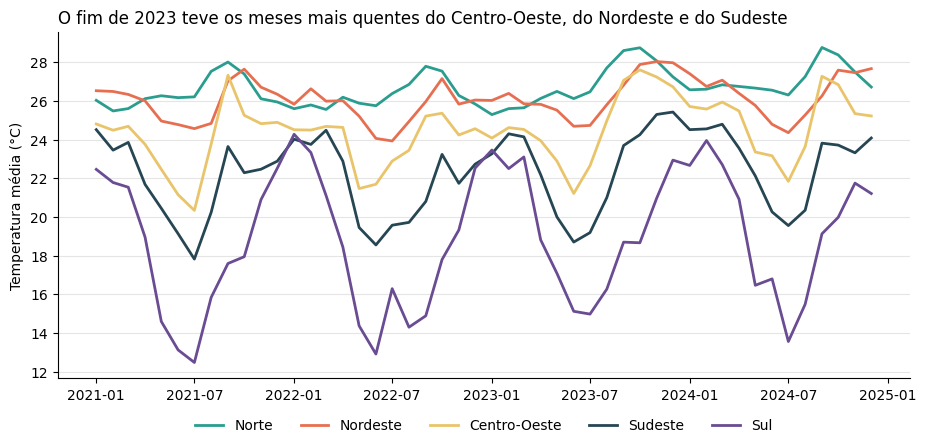

In [23]:
g = gold_mensal_regiao.copy()
g["periodo"] = pd.to_datetime(dict(year=g["ano"], month=g["mes"], day=1))
fig, ax = plt.subplots(figsize=(11, 4.5))
for reg in ORDEM_REG:
    x = g[g["regiao"] == reg]
    ax.plot(x["periodo"], x["temperatura"], color=CORES[reg], lw=2, label=reg)
ax.set_ylabel("Temperatura média (°C)")
ax.set_title(TITULOS["serie_temperatura"], loc="left")
ax.legend(ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.08))
ax.grid(axis="y", color="#e5e5e5")
salvar(fig, "01_serie_temperatura_regiao")

### 5.2 Tendência: média anual com as mesmas estações nos 4 anos

Estações usadas: 153 de 584


ano,2021,2022,2023,2024,variacao_2021_2024
regiao,,,,,
Norte,27.010000,27.230000,27.959999,28.370001,1.36
Nordeste,25.680000,25.340000,26.020000,25.950001,0.27
Centro-Oeste,23.080000,22.940001,23.639999,23.840000,0.76
Sudeste,21.490000,21.360001,22.309999,22.629999,1.14
Sul,18.120001,17.959999,18.920000,18.950001,0.83


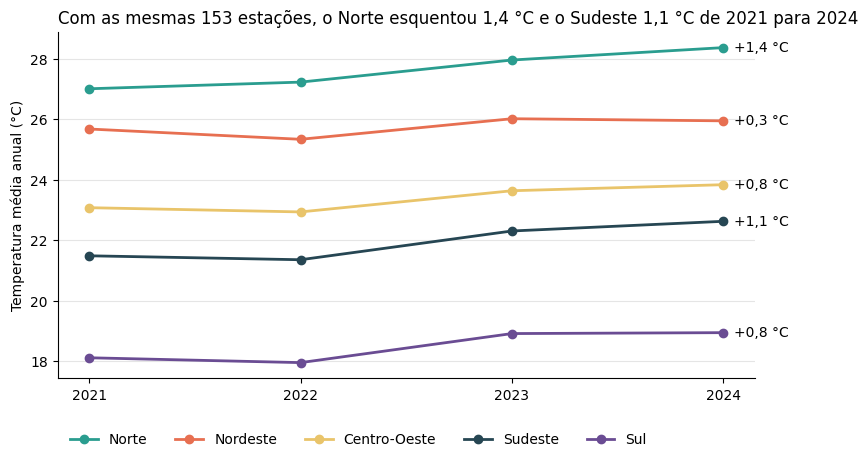

In [24]:
# só entram estações com pelo menos 80% das horas válidas em todos os anos (assim a comparação é justa)
horas_ano = {2021: 8760, 2022: 8760, 2023: 8760, 2024: 8784}
e = gold_anual_estacao.copy()
e["cobertura"] = e["horas_validas"] / e["ano"].map(horas_ano)
boas = e[e["cobertura"] >= 0.8].groupby("codigo_wmo")["ano"].nunique()
fixas = boas[boas == len(coleta.ANOS)].index
tendencia = (e[e["codigo_wmo"].isin(fixas)].groupby(["regiao", "ano"], observed=True)["temperatura"].mean()
               .unstack("ano").reindex(ORDEM_REG).round(2))
tendencia["variacao_2021_2024"] = (tendencia[2024] - tendencia[2021]).round(2)
print(f"Estações usadas: {len(fixas)} de {e['codigo_wmo'].nunique()}")
display(tendencia)

fig, ax = plt.subplots(figsize=(9, 4.5))
for reg in ORDEM_REG:
    ax.plot(coleta.ANOS, tendencia.loc[reg, coleta.ANOS], color=CORES[reg], marker="o", lw=2, label=reg)
    ax.annotate(f"{tendencia.loc[reg, 'variacao_2021_2024']:+.1f} °C".replace(".", ","), (2024, tendencia.loc[reg, 2024]),
                xytext=(8, 0), textcoords="offset points", va="center")
ax.set_xticks(coleta.ANOS); ax.set_ylabel("Temperatura média anual (°C)")
ax.set_title(TITULOS["tendencia"], loc="left")
ax.legend(ncol=5, frameon=False, loc="upper left", bbox_to_anchor=(0, -0.12))
ax.grid(axis="y", color="#e5e5e5")
salvar(fig, "02_tendencia_temperatura")

### 5.3 Barras ordenadas: chuva anual média por UF

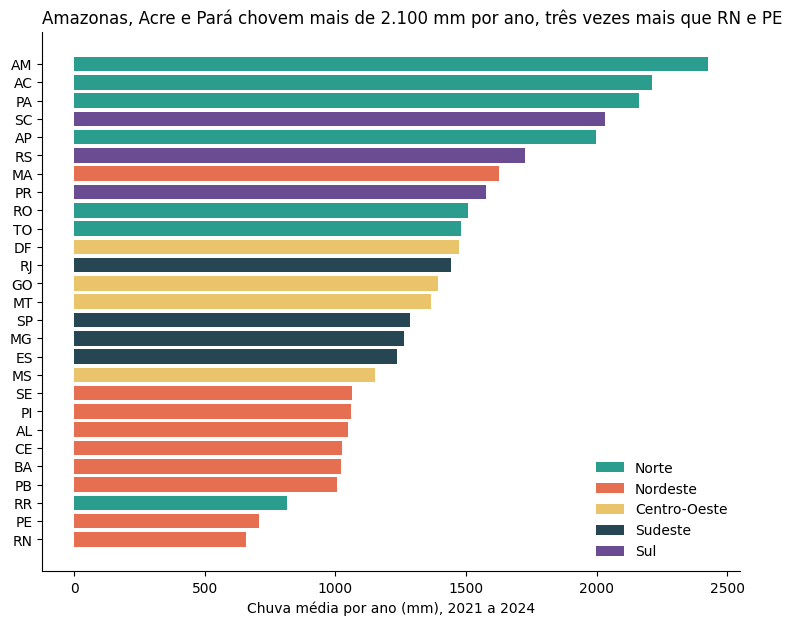

,uf,regiao,chuva_mm
13,PA,Norte,2163.167712
0,AC,Norte,2212.323188
2,AM,Norte,2427.222477


,uf,regiao,chuva_mm
19,RN,Nordeste,657.950978
15,PE,Nordeste,705.995910
21,RR,Norte,813.241321


In [25]:
chuva_uf = (gold_mensal_uf.groupby(["uf", "regiao", "ano"], observed=True)["chuva_mm"].sum()
              .groupby(["uf", "regiao"], observed=True).mean().reset_index().sort_values("chuva_mm"))
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(chuva_uf["uf"], chuva_uf["chuva_mm"], color=[CORES[r] for r in chuva_uf["regiao"]])
ax.set_xlabel("Chuva média por ano (mm), 2021 a 2024")
ax.set_title(TITULOS["chuva_uf"], loc="left")
for reg in ORDEM_REG:
    ax.bar(0, 0, color=CORES[reg], label=reg)
ax.legend(frameon=False, loc="lower right")
salvar(fig, "03_chuva_anual_uf")
display(chuva_uf.tail(3)); display(chuva_uf.head(3))

### 5.4 Sazonalidade da chuva por região

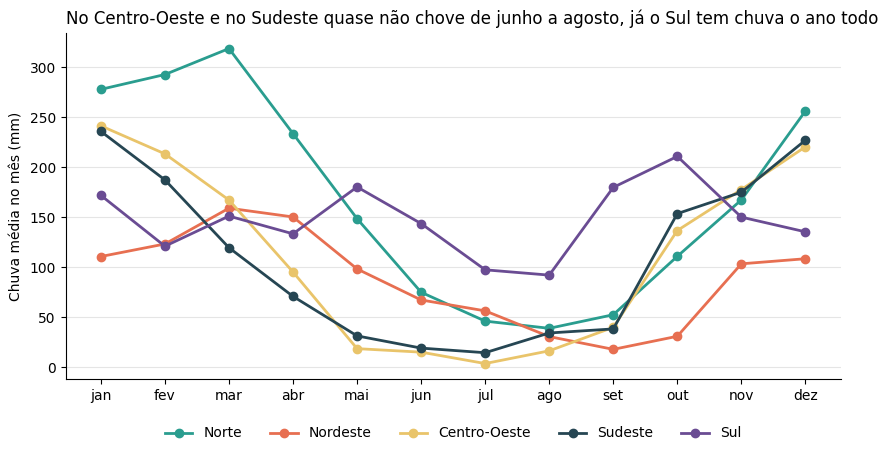

regiao,Norte,Nordeste,Centro-Oeste,Sudeste,Sul
mes,,,,,
1,278.0,111.0,242.0,236.0,172.0
2,293.0,123.0,214.0,188.0,121.0
3,319.0,159.0,167.0,120.0,151.0
4,234.0,150.0,95.0,71.0,134.0
5,149.0,99.0,19.0,32.0,180.0
6,75.0,67.0,15.0,19.0,144.0
7,46.0,57.0,4.0,15.0,98.0
8,39.0,31.0,17.0,34.0,92.0
9,53.0,18.0,40.0,39.0,180.0


In [26]:
saz = gold_mensal_regiao.groupby(["regiao", "mes"], observed=True)["chuva_mm"].mean().unstack("regiao")[ORDEM_REG]
fig, ax = plt.subplots(figsize=(10, 4.5))
for reg in ORDEM_REG:
    ax.plot(saz.index, saz[reg], color=CORES[reg], marker="o", lw=2, label=reg)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"])
ax.set_ylabel("Chuva média no mês (mm)")
ax.set_title(TITULOS["sazonalidade_chuva"], loc="left")
ax.legend(ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1)); ax.grid(axis="y", color="#e5e5e5")
salvar(fig, "04_sazonalidade_chuva")
display(saz.round(0))

### 5.5 Mapa: % das horas com calor extremo por UF

UFs do mapa sem dado: 0


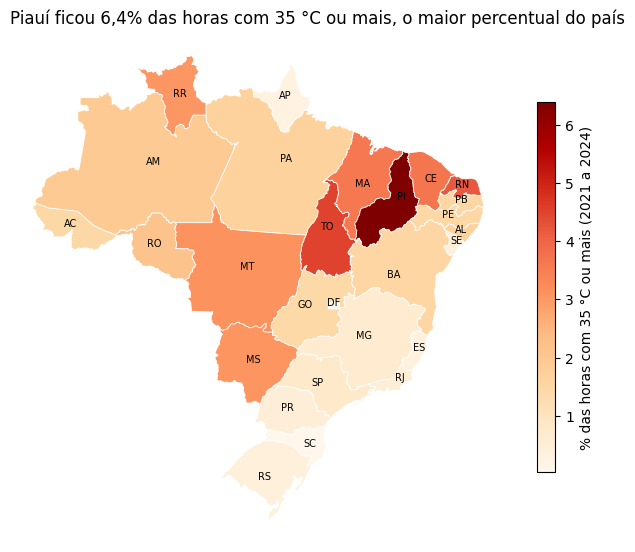

,uf,codigo_uf,horas_calor,horas_validas,pct_calor
16,PI,22,30661.0,480211,6.38
26,TO,17,20943.0,463807,4.52
19,RN,24,5449.0,130190,4.19
5,CE,23,10737.0,293462,3.66
9,MA,21,13498.0,374038,3.61


In [27]:
import geopandas as gpd

calor_uf = (gold_mensal_uf.assign(horas_calor=gold_mensal_uf["pct_calor"] / 100 * gold_mensal_uf["horas_validas"])
              .groupby(["uf", "codigo_uf"], observed=True)[["horas_calor", "horas_validas"]].sum().reset_index())
calor_uf["pct_calor"] = calor_uf["horas_calor"] / calor_uf["horas_validas"] * 100

mapa = gpd.read_file(BRONZE / "ibge" / "malha_uf.json")
mapa["codigo_uf"] = mapa["codarea"].astype(int)
mapa = mapa.merge(calor_uf, on="codigo_uf", how="left")
print("UFs do mapa sem dado:", mapa["pct_calor"].isna().sum())

fig, ax = plt.subplots(figsize=(8, 8))
mapa.plot(column="pct_calor", cmap="OrRd", legend=True, edgecolor="white", linewidth=0.6, ax=ax,
          legend_kwds={"label": "% das horas com 35 °C ou mais (2021 a 2024)", "shrink": 0.6})
for _, linha in mapa.iterrows():
    p = linha.geometry.representative_point()
    ax.annotate(linha["uf"], (p.x, p.y), ha="center", fontsize=7)
ax.set_axis_off()
ax.set_title(TITULOS["mapa_calor"], loc="left")
salvar(fig, "05_mapa_calor_extremo")
display(calor_uf.sort_values("pct_calor", ascending=False).head(5).round(2))

### 5.6 Calor extremo ano a ano nas UFs mais quentes

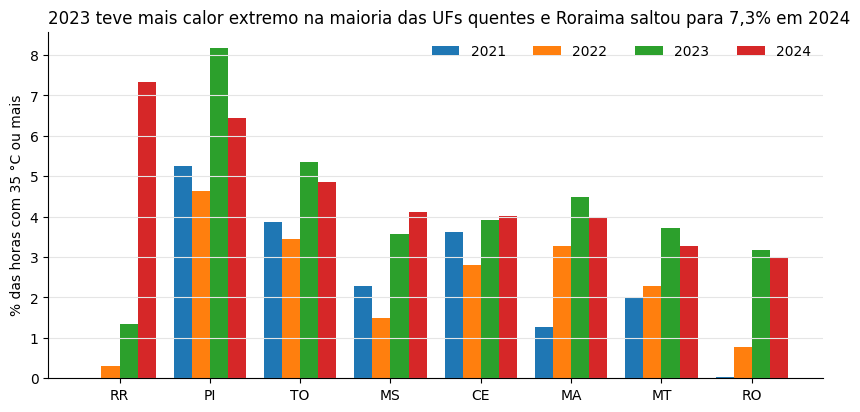

ano,2021,2022,2023,2024
uf,,,,
RR,0.00,0.30,1.35,7.32
PI,5.26,4.64,8.17,6.43
TO,3.86,3.44,5.34,4.87
MS,2.29,1.49,3.56,4.11
CE,3.62,2.81,3.91,4.02
MA,1.26,3.26,4.49,4.00
MT,2.02,2.28,3.73,3.28
RO,0.03,0.77,3.19,2.97


In [28]:
calor_ano = (gold_mensal_uf.assign(horas_calor=gold_mensal_uf["pct_calor"] / 100 * gold_mensal_uf["horas_validas"])
               .groupby(["uf", "ano"], observed=True)[["horas_calor", "horas_validas"]].sum())
calor_ano = (calor_ano["horas_calor"] / calor_ano["horas_validas"] * 100).unstack("ano")
top = calor_ano.sort_values(2024, ascending=False).head(8)
fig, ax = plt.subplots(figsize=(10, 4.5))
largura = 0.2
for i, ano in enumerate(coleta.ANOS):
    ax.bar(np.arange(len(top)) + i * largura, top[ano], width=largura, label=str(ano))
ax.set_xticks(np.arange(len(top)) + 1.5 * largura); ax.set_xticklabels(top.index)
ax.set_ylabel("% das horas com 35 °C ou mais")
ax.set_title(TITULOS["calor_ano"], loc="left")
ax.legend(frameon=False, ncol=4); ax.grid(axis="y", color="#e5e5e5")
salvar(fig, "06_calor_extremo_por_ano")
display(top.round(2))

### 5.7 Distribuição da umidade nos meses secos por região

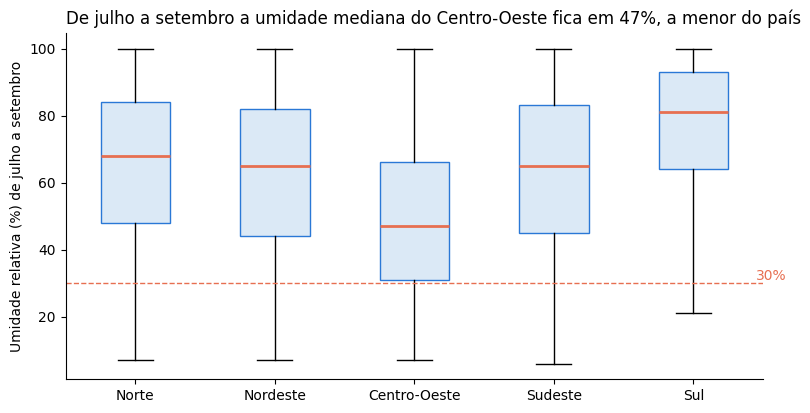

regiao
Centro-Oeste    47.0
Nordeste        65.0
Norte           68.0
Sudeste         65.0
Sul             81.0


In [29]:
fig, ax = plt.subplots(figsize=(9, 4.5))
dados = [umidade_seca.loc[umidade_seca["regiao"] == reg, "umidade_pct"] for reg in ORDEM_REG]
ax.boxplot(dados, showfliers=False, patch_artist=True,
           boxprops=dict(facecolor="#dbe9f6", color="#2a78d6"), medianprops=dict(color="#e76f51", lw=2))
ax.set_xticks(range(1, 6)); ax.set_xticklabels(ORDEM_REG)
ax.axhline(30, color="#e76f51", ls="--", lw=1)
ax.text(5.45, 31, "30%", color="#e76f51")
ax.set_ylabel("Umidade relativa (%) de julho a setembro")
ax.set_title(TITULOS["boxplot_umidade"], loc="left")
salvar(fig, "07_boxplot_umidade_meses_secos")
print((umidade_seca.groupby("regiao", observed=True)["umidade_pct"].median()).round(1).to_string())

### 5.8 Umidade abaixo de 30% ao longo do ano

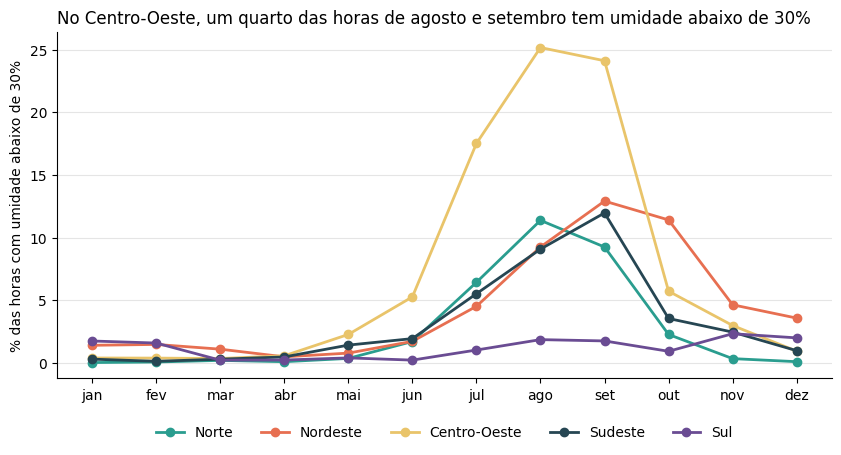

regiao,Norte,Nordeste,Centro-Oeste,Sudeste,Sul
mes,,,,,
1,0.0,1.4,0.400000,0.3,1.7
2,0.1,1.5,0.400000,0.1,1.6
3,0.2,1.1,0.400000,0.3,0.2
4,0.1,0.5,0.600000,0.5,0.2
5,0.4,0.8,2.300000,1.4,0.4
6,1.7,1.7,5.300000,1.9,0.2
7,6.4,4.5,17.500000,5.5,1.0
8,11.4,9.2,25.200001,9.1,1.9
9,9.2,12.9,24.100000,12.0,1.8


In [30]:
umid = gold_mensal_regiao.groupby(["regiao", "mes"], observed=True)["pct_umid_baixa"].mean().unstack("regiao")[ORDEM_REG]
fig, ax = plt.subplots(figsize=(10, 4.5))
for reg in ORDEM_REG:
    ax.plot(umid.index, umid[reg], color=CORES[reg], marker="o", lw=2, label=reg)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"])
ax.set_ylabel("% das horas com umidade abaixo de 30%")
ax.set_title(TITULOS["umidade_baixa"], loc="left")
ax.legend(ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1)); ax.grid(axis="y", color="#e5e5e5")
salvar(fig, "08_umidade_baixa_mes")
display(umid.round(1))

### 5.9 Relação entre as variáveis: mapa de calor da correlação

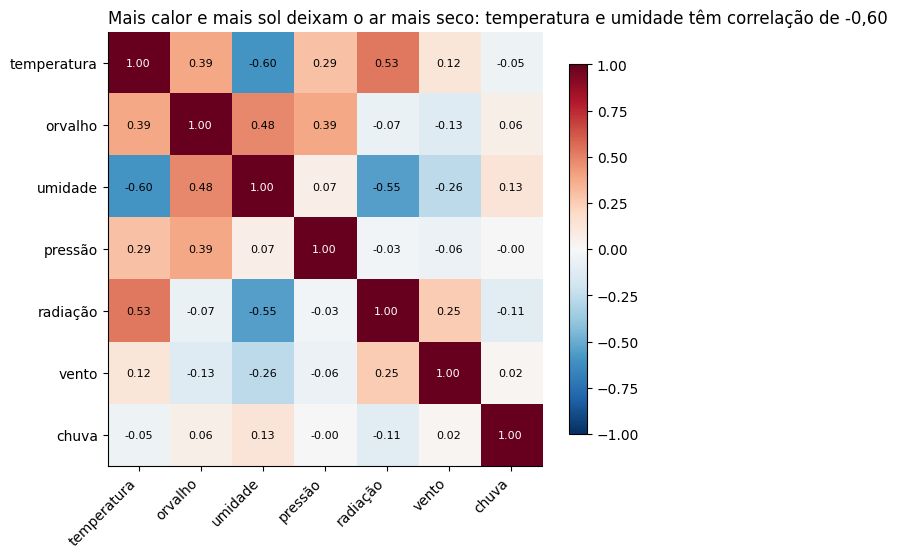

In [31]:
nomes_curtos = ["temperatura", "orvalho", "umidade", "pressão", "radiação", "vento", "chuva"]
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(nomes_curtos))); ax.set_xticklabels(nomes_curtos, rotation=45, ha="right")
ax.set_yticks(range(len(nomes_curtos))); ax.set_yticklabels(nomes_curtos)
for i in range(len(nomes_curtos)):
    for j in range(len(nomes_curtos)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.values[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title(TITULOS["correlacao"], loc="left")
salvar(fig, "09_correlacao")

### 5.10 El Niño × La Niña

,fase_enso,regiao,temp_anomalia,chuva_anomalia_pct
0,El Niño,Centro-Oeste,0.89,13.31
1,El Niño,Nordeste,0.53,-11.10
2,El Niño,Norte,0.57,-8.25
3,El Niño,Sudeste,0.74,8.21
4,El Niño,Sul,0.63,31.79
5,La Niña,Centro-Oeste,-0.44,-6.14
6,La Niña,Nordeste,-0.30,17.32
7,La Niña,Norte,-0.38,14.78
8,La Niña,Sudeste,-0.51,2.04
9,La Niña,Sul,-0.47,-11.51


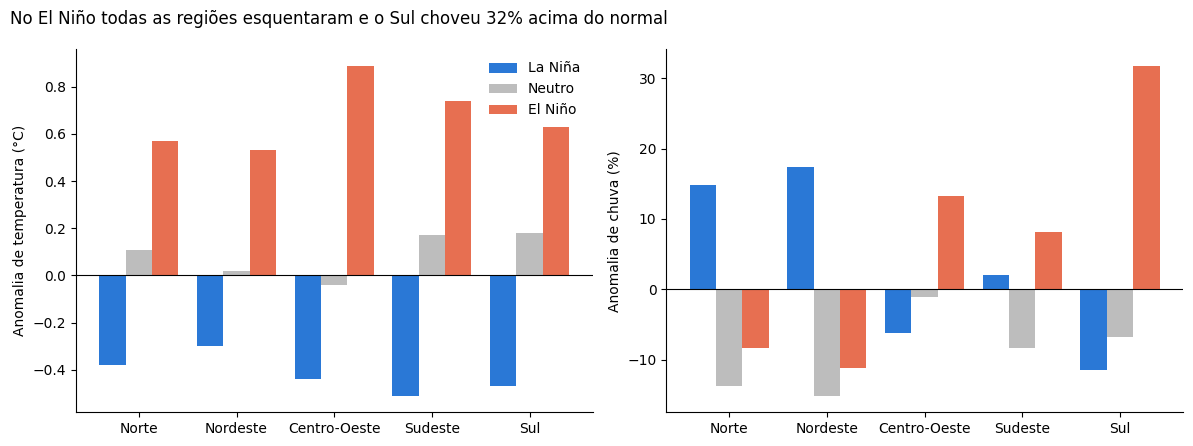

In [32]:
# anomalia: quanto o mês ficou acima ou abaixo da média daquele mês nos 4 anos, em cada região
m = gold_mensal_regiao.copy()
m["temp_anomalia"] = m["temperatura"] - m.groupby(["regiao", "mes"], observed=True)["temperatura"].transform("mean")
m["chuva_anomalia_pct"] = (m["chuva_mm"] / m.groupby(["regiao", "mes"], observed=True)["chuva_mm"].transform("mean") - 1) * 100
enso = (m.groupby(["fase_enso", "regiao"], observed=True)[["temp_anomalia", "chuva_anomalia_pct"]].mean()
          .round(2).reset_index())
display(enso)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
fases = ["La Niña", "Neutro", "El Niño"]
cores_fase = {"La Niña": "#2a78d6", "Neutro": "#bdbdbd", "El Niño": "#e76f51"}
for k, (coluna, rotulo) in enumerate([("temp_anomalia", "Anomalia de temperatura (°C)"), ("chuva_anomalia_pct", "Anomalia de chuva (%)")]):
    for i, fase in enumerate(fases):
        v = enso[enso["fase_enso"] == fase].set_index("regiao").reindex(ORDEM_REG)[coluna]
        axes[k].bar(np.arange(5) + i * 0.27, v, width=0.27, color=cores_fase[fase], label=fase)
    axes[k].axhline(0, color="black", lw=0.8)
    axes[k].set_xticks(np.arange(5) + 0.27); axes[k].set_xticklabels(ORDEM_REG)
    axes[k].set_ylabel(rotulo)
axes[0].legend(frameon=False)
fig.suptitle(TITULOS["enso"], x=0.01, ha="left")
plt.tight_layout()
salvar(fig, "10_el_nino_la_nina")

### 5.11 Antes × depois da limpeza

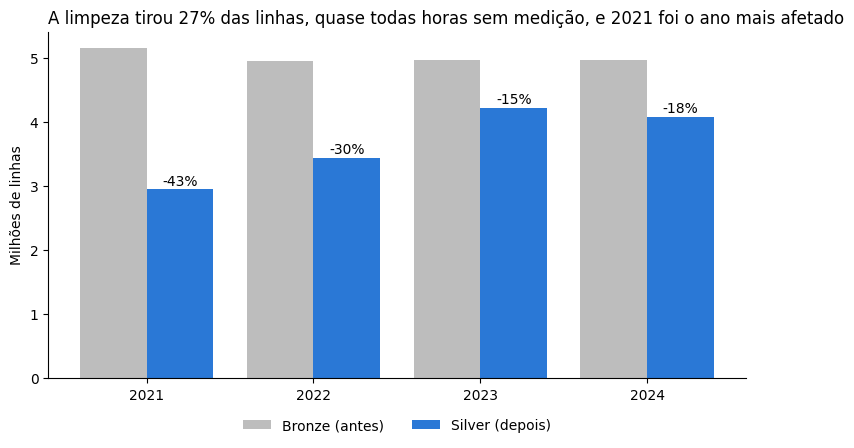

In [33]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(tab_log))
ax.bar(x - 0.2, tab_log["linhas_bronze"] / 1e6, width=0.4, color="#bdbdbd", label="Bronze (antes)")
ax.bar(x + 0.2, tab_log["linhas_silver"] / 1e6, width=0.4, color="#2a78d6", label="Silver (depois)")
for i, linha in tab_log.iterrows():
    perda = (1 - linha["linhas_silver"] / linha["linhas_bronze"]) * 100
    ax.annotate(f"-{perda:.0f}%", (i + 0.2, linha["linhas_silver"] / 1e6), xytext=(0, 3), textcoords="offset points", ha="center")
ax.set_xticks(x); ax.set_xticklabels(tab_log["ano"])
ax.set_ylabel("Milhões de linhas")
ax.set_title(TITULOS["antes_depois"], loc="left")
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.08))
salvar(fig, "11_antes_depois_limpeza")

## 6. Respostas às perguntas

**1. A temperatura média subiu de 2021 para 2024?**
Sim, em todas as regiões. Para a comparação ser justa, usei só as 153 estações que tiveram dados em pelo menos 80% das horas nos 4 anos. O Norte subiu 1,4 °C (de 27,0 para 28,4 °C), o Sudeste 1,1 °C, o Sul e o Centro-Oeste 0,8 °C e o Nordeste 0,3 °C. O maior salto foi de 2022 para 2023, quando chegou o El Niño.

**2. Como a chuva se distribui e quais UFs são mais secas ou chuvosas?**
O Norte é a região que mais chove, com Amazonas (2.427 mm por ano), Acre e Pará no topo. As mais secas são Rio Grande do Norte (658 mm) e Pernambuco (706 mm), puxadas pelas estações do sertão. No Centro-Oeste e no Sudeste a chuva vem de outubro a março e quase some de junho a agosto. O Sul chove o ano todo, entre 92 e 211 mm por mês.

**3. Onde e quando teve mais calor extremo?**
No Piauí, com 6,4% das horas a 35 °C ou mais, depois Tocantins (4,5%) e Rio Grande do Norte (4,2%). No Sul e no Sudeste quase não acontece. 2023 foi o pior ano na maioria das UFs quentes. Roraima foi de 0% em 2021 para 7,3% em 2024, mas lá tem só uma estação, então esse número precisa de cuidado.

**4. Quando a umidade fica abaixo de 30%?**
De julho a setembro. O Centro-Oeste é o pior caso, com um quarto das horas de agosto e setembro abaixo de 30%. O Nordeste chega a 13% das horas em setembro, o Sudeste a 12% e o Norte a 11% em agosto. No Sul quase não acontece.

**5. El Niño e La Niña foram diferentes?**
Sim. Comparando cada mês com a média daquele mês nos 4 anos, os meses de El Niño ficaram de 0,5 a 0,9 °C mais quentes em todas as regiões, e os de La Niña de 0,3 a 0,5 °C mais frios. Na chuva depende da região. Com El Niño o Sul choveu 32% acima da média e o Nordeste e o Norte choveram 11% e 8% abaixo. Com La Niña foi o contrário, com Nordeste 17% e Norte 15% acima e Sul 12% abaixo.
Uma ressalva: só 11 meses foram de El Niño, todos em 2023 e 2024, que também foram os anos mais quentes. Então parte desse calor pode ser tendência e não só efeito do El Niño.


## 7. Resumo do pipeline

In [34]:
print("FUNIL DO DATA LAKE")
print(f"  Bronze  {int(tab_log['linhas_bronze'].sum()):>12,} linhas  ({len(meta):,} CSVs do INMET em Parquet)")
print(f"  Silver  {int(tab_log['linhas_silver'].sum()):>12,} linhas  (limpa, com IBGE e ONI)")
for nome, tabela in [("gold_mensal_regiao", gold_mensal_regiao), ("gold_mensal_uf", gold_mensal_uf),
                     ("gold_anual_estacao", gold_anual_estacao)]:
    print(f"  Gold    {len(tabela):>12,} linhas  ({nome})")
print(f"\nFiguras salvas em {FIGURAS}: {len(list(FIGURAS.glob('*.png')))}")
shutil.rmtree(TMP_LOCAL, ignore_errors=True)
status()

FUNIL DO DATA LAKE
  Bronze    20,029,680 linhas  (2,287 CSVs do INMET em Parquet)
  Silver    14,692,522 linhas  (limpa, com IBGE e ONI)
  Gold             240 linhas  (gold_mensal_regiao)
  Gold           1,275 linhas  (gold_mensal_uf)
  Gold           2,127 linhas  (gold_anual_estacao)

Figuras salvas em /content/drive/MyDrive/Geral/projeto_inmet/reports/figuras: 11
  data/bronze      120 arquivos      674.8 MB
  data/silver      112 arquivos      347.9 MB
  data/gold          3 arquivos        0.1 MB
